
# Experiment 3: zones with a distance-aware loss

`experiment_zones.ipynb` trained the zone classifiers with **cross-entropy**, which only looks at the probability given to the true zone: calling the neighbouring zone is as wrong as calling a zone across the room. Here the **training loss itself has a notion of distance**.

## The loss
For a window with true position `r` (meters), a network that gives probability `p_k` to zone `k` whose centre is at `c_k`:

&nbsp;&nbsp;&nbsp;&nbsp;`loss = sum_k p_k * |c_k - r| / zone_size   +   0.1 * cross_entropy`

* The first term is the **expected distance** from the zone the network would draw at random from its own probabilities to the speaker, in units of cells. Probability on a neighbouring zone costs a little; probability far away costs a lot. It is the same quantity as the "distance from the predicted zone centre to the true position" that the results report, so the model is trained on what it is judged on.
* The distance is taken to the speaker's **exact position**, not to the true zone's centre, so a speaker standing near a cell boundary pulls probability toward the neighbouring cell too.
* The small cross-entropy term (weight 0.1) keeps the output a proper set of probabilities (needed for top-3 and the confusion matrix) and keeps training stable at the start; without it, the distance term alone is happy with any spread of probability around the right place.
* **Epoch count** is chosen on the validation set by the **mean distance** of the predicted zone's centre (smoothed over epochs), not by accuracy, so the stopping rule matches the loss. The headline model is the one with the lowest validation mean distance.

## What is the same
Everything else as in `experiment_zones.ipynb`: data and windows, the three inputs, the network architectures (one output per zone), the optimisers, the split (train / validate on sessions 1 and 2, test once on session 3), 50 cm zones for the main run, the baselines, and the zone-size sweep for the 8-band MLP. A comparison section at the end puts this run next to the cross-entropy run (read from `trained_models_zones/`) on the same test windows.

## What to expect, and what to read carefully
* An expected-distance loss rewards answers that are *close* even when not exactly right, so **exact-zone accuracy can drop while the distance improves**. Both are reported; neither is the single right metric.
* The distance metric has a floor: a correct zone is still up to 0.7 x the cell size from the true position. Smaller cells lower that floor but are harder to get exactly right.
* The same caveats as before apply: zones never seen in training cannot be predicted (the classes are the zones seen in training), and session 3 is a single session.
* Weights and predictions are saved as each model finishes, in `trained_models_zones_distance/`; the scores are in `results_zones.json` there.


In [1]:
from pathlib import Path
import csv, json

import numpy as np
import torch
from scipy.io import wavfile
from scipy.signal import butter, resample_poly, sosfiltfilt
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt

# ---- knobs ----
WINDOW_LEN = 1.0      # seconds of audio in each window
STEP_LEN = 0.5        # seconds between window starts (STEP_LEN < WINDOW_LEN: windows overlap)
BATCH_SIZE = 32
SESSIONS = [1, 2, 3]
SKIP_INTRO = True     # skip the start claps and the talking before them (meta.json: usable_from_s)
MAX_LABEL_GAP = 0.15  # s; drop a window if no tracked position lies this close to its centre
SR_OUT = 16000        # audio is resampled from 48 kHz to this (speech needs no more; 1 sample = 2.1 cm of path difference)
BANDPASS = (300, 4000)  # Hz, zero-phase filter applied to every channel the same way; None = leave the band alone
SILENCE_DB = None     # drop windows whose loudest channel is below this level (dB re full scale); None = keep all

DATASET_DIR = Path("../presets/apartment/dataset")

QUICK = False          # True = a few epochs only, to test the notebook
MAXE = dict(mlp=3, spec=3, raw=3) if QUICK else dict(mlp=100, spec=60, raw=40)
ZONE = 0.5            # m, zone side for the main run
ZONE_SWEEP = [0.5, 1.0] if QUICK else [0.25, 0.5, 0.75, 1.0]
SAVE_DIR = Path('trained_models_zones_distance' + ('_quick' if QUICK else '')); SAVE_DIR.mkdir(exist_ok=True)

## Data (same code as `experiment.ipynb`)

In [2]:
def preprocess(audio_i16, sr_in, sr_out, bandpass):
    # (samples, 3) int16 at sr_in -> (3, samples) float32 at sr_out, band-passed (zero phase)
    out = []
    for c in range(audio_i16.shape[1]):
        x = audio_i16[:, c].astype(np.float32) / 32768.0
        if sr_out != sr_in:
            g = np.gcd(sr_in, sr_out)
            x = resample_poly(x, sr_out // g, sr_in // g).astype(np.float32)
        if bandpass:
            x = sosfiltfilt(butter(4, bandpass, "bandpass", fs=sr_out, output="sos"), x).astype(np.float32)
        out.append(x)
    return np.stack(out)


class WindowedSessions(Dataset):
    def __init__(self, root=DATASET_DIR, sessions=SESSIONS, window_len=WINDOW_LEN, step_len=STEP_LEN,
                 skip_intro=SKIP_INTRO, max_label_gap=MAX_LABEL_GAP, sr_out=SR_OUT, bandpass=BANDPASS, silence_db=SILENCE_DB):
        self.window_len, self.step_len, self.sr = window_len, step_len, sr_out
        self.audio, self.sessions, self.phones = {}, {}, None
        self.W = round(window_len * sr_out)
        S = round(step_len * sr_out)
        index = []                                    # (session, start sample, centre time s, x m, y m, level dB)
        for n in sessions:
            d = Path(root) / f"session{n}"
            sr_in, raw = wavfile.read(d / "audio_abc.wav", mmap=True)       # (samples, 3) int16
            meta = json.load(open(d / "meta.json"))
            x = preprocess(raw, sr_in, sr_out, bandpass)                    # (3, samples)
            self.audio[n] = x
            self.phones = {p: tuple(v) for p, v in meta["phones_xy_m"].items()}
            rows = [r for r in csv.DictReader(open(d / "positions.csv")) if r["x_m"] != ""]
            t = np.array([float(r["t_audio_s"]) for r in rows])
            xy = np.array([[float(r["x_m"]), float(r["y_m"])] for r in rows])
            self.sessions[n] = dict(t=t, xy=xy, usable_from=meta["usable_from_s"] if skip_intro else 0.0)

            cs = np.concatenate([np.zeros((3, 1)), np.cumsum(x.astype(np.float64) ** 2, axis=1)], axis=1)
            first = round(self.sessions[n]["usable_from"] * sr_out)
            for start in range(first, x.shape[1] - self.W + 1, S):
                tc = (start + self.W / 2) / sr_out
                k = np.searchsorted(t, tc)
                near = min((abs(t[j] - tc) for j in (k - 1, k) if 0 <= j < len(t)), default=np.inf)
                if near > max_label_gap:
                    continue
                level = 10 * np.log10(((cs[:, start + self.W] - cs[:, start]) / self.W).max() + 1e-12)
                if silence_db is not None and level < silence_db:
                    continue
                index.append((n, start, tc, np.interp(tc, t, xy[:, 0]), np.interp(tc, t, xy[:, 1]), level))
        self.index = index

    def __len__(self):
        return len(self.index)

    def __getitem__(self, i):
        n, start, tc, x, y, level = self.index[i]
        return dict(audio=torch.from_numpy(self.audio[n][:, start:start + self.W].copy()), xy=torch.tensor([x, y], dtype=torch.float32),
                    level_db=torch.tensor(level, dtype=torch.float32), session=n, t_center=tc)

    def summary(self):
        for n in self.sessions:
            k = sum(1 for r in self.index if r[0] == n)
            print(f"session {n}: {k} windows")
        print(f"total {len(self)} windows of {self.window_len} s, step {self.step_len} s, {self.sr} Hz")


ds = WindowedSessions()
ds.summary()
loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
batch = next(iter(loader))
print({k: (tuple(v.shape), v.dtype) if torch.is_tensor(v) else type(v) for k, v in batch.items()})

session 1: 1001 windows
session 2: 1136 windows
session 3: 826 windows
total 2963 windows of 1.0 s, step 0.5 s, 16000 Hz
{'audio': ((32, 3, 16000), torch.float32), 'xy': ((32, 2), torch.float32), 'level_db': ((32,), torch.float32), 'session': ((32,), torch.int64), 't_center': ((32,), torch.float64)}


In [3]:
fs = ds.sr; BAND = (300, 4000)
import torch.nn as nn, torch.nn.functional as F

# the label of every window, in the dataset's order (rows of ds.index: session, start, centre time, x, y, level)
truth = np.array([r[3:5] for r in ds.index])           # meters
sess = np.array([r[0] for r in ds.index])
t_centre = np.array([r[2] for r in ds.index])
P = np.array([ds.phones[p] for p in "ABC"])             # phone positions on the floor, meters
C_SOUND = 343.0                                         # m/s
MOUTH_Z = 1.45                                          # m, assumed height of the voice above the phones on the floor

def err_cm(pred):
    return np.linalg.norm(pred - truth, axis=1) * 100

def report(name, err):
    row = lambda e: f"median {np.median(e):6.1f}   mean {e.mean():6.1f}   p90 {np.percentile(e, 90):6.1f}"
    print(f"{name:<34} all: {row(err)}")
    for n in SESSIONS:
        print(f"{'':<34} s{n}:  {row(err[sess == n])}")

## Inputs (same features as before)

In [4]:
BANDS = np.geomspace(300, 4000, 9)                    # 8 bands, equal width on a log-frequency axis
win = np.hanning(ds.W).astype(np.float32)
freq = np.fft.rfftfreq(ds.W, 1 / fs)
masks = [(freq >= lo) & (freq < hi) for lo, hi in zip(BANDS[:-1], BANDS[1:])]

def band_levels(audio):
    # (B, 3, W) -> (B, 3, 8) loudness in dB per phone and band
    p = np.abs(np.fft.rfft(audio * win, axis=-1)) ** 2
    return 10 * np.log10(np.stack([p[..., m].sum(-1) for m in masks], -1) + 1e-12)

L = np.concatenate([band_levels(b["audio"].numpy()) for b in DataLoader(ds, batch_size=64, shuffle=False)])    # (windows, 3, 8)
broad = 10 * np.log10((10 ** (L / 10)).sum(-1))                      # (windows, 3): all bands together
X_broad = broad - broad.mean(1, keepdims=True)                       # relative to the phone average
X_band = (L - L.mean(1, keepdims=True)).reshape(len(L), -1)          # (windows, 24)
Y = truth.copy()                                                      # meters
print("features:", X_broad.shape, X_band.shape)

features: (2963, 3) (2963, 24)


In [5]:
# log-mel spectrograms, relative to the phone average (as in experiment.ipynb, section 4b)
N_FFT, HOP, N_MELS = 512, 160, 32

def mel_filters():
    mel = lambda f: 2595 * np.log10(1 + f / 700); imel = lambda m: 700 * (10 ** (m / 2595) - 1)
    edges = imel(np.linspace(mel(BAND[0]), mel(BAND[1]), N_MELS + 2))
    fr = np.fft.rfftfreq(N_FFT, 1 / fs); fb = np.zeros((N_MELS, len(fr)), np.float32)
    for m in range(N_MELS):
        lo, mid, hi = edges[m:m + 3]
        fb[m] = np.clip(np.minimum((fr - lo) / (mid - lo), (hi - fr) / (hi - mid)), 0, None)
    return torch.tensor(fb)

FB = mel_filters(); STFT_WIN = torch.hann_window(N_FFT)
def logmel(audio):
    B = audio.shape[0]
    p = torch.stft(audio.reshape(B * 3, -1), N_FFT, HOP, window=STFT_WIN, return_complex=True).abs() ** 2
    s = 10 * torch.log10(torch.einsum("mf,bft->bmt", FB, p) + 1e-10).reshape(B, 3, N_MELS, -1)
    return (s - s.mean(1, keepdim=True)).numpy()

S = np.concatenate([logmel(b["audio"]) for b in DataLoader(ds, batch_size=64, shuffle=False)])
X_raw = np.concatenate([b["audio"].numpy() for b in DataLoader(ds, batch_size=64, shuffle=False)])
print("inputs per window: 8-band", X_band.shape[1], "| log-mel", S[0].shape, "=", S[0].size, "| raw", X_raw[0].shape, "=", X_raw[0].size)

# the three networks of experiment.ipynb; only the last layer changes: one score per zone (k) instead of (x, y)
def make_mlp_cls(d, k):
    return nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Dropout(0.1), nn.Linear(64, 64), nn.ReLU(), nn.Dropout(0.1), nn.Linear(64, k))
def make_spec_cnn(k):
    def blk(i, o): return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2)]
    return nn.Sequential(*blk(3, 8), *blk(8, 16), *blk(16, 32), nn.AdaptiveAvgPool2d((4, 1)), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, k))
def make_raw_cnn(k):
    def blk(i, o, kk, s, drop): return [nn.Conv1d(i, o, kk, stride=s), nn.BatchNorm1d(o), nn.ReLU()] + ([nn.Dropout(drop)] if drop else [])
    return nn.Sequential(*blk(3, 16, 80, 16, 0), *blk(16, 16, 9, 4, 0.2), *blk(16, 32, 9, 4, 0.2), nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.5), nn.Linear(32, k))

inputs per window: 8-band 24 | log-mel (3, 32, 101) = 9696 | raw (3, 16000) = 48000


## Split (identical to `experiment.ipynb`)
Train and validate on sessions 1 and 2, the first 80% of each session (in time order) for training and the last 20% for validation, with training windows within 2 s of the boundary dropped; the final fit uses all windows of sessions 1 and 2; the test is session 3 only.

In [6]:
GAP = 2.0
tr_idx, va_idx = [], []
for n in (1, 2):
    ix = np.where(sess == n)[0]
    cut = int(round(0.8 * len(ix)))
    t_b = t_centre[ix[cut]]
    va_idx += list(ix[cut:])
    tr_idx += [i for i in ix[:cut] if t_centre[i] <= t_b - GAP]
tr_idx, va_idx = np.array(tr_idx), np.array(va_idx)
fit_idx, te_idx = np.where(sess != 3)[0], np.where(sess == 3)[0]
print(f"train {len(tr_idx)}  validation {len(va_idx)}  (sessions 1+2)   final fit {len(fit_idx)}   test {len(te_idx)} (session 3)")

train 1704  validation 427  (sessions 1+2)   final fit 2137   test 826 (session 3)


## Zones
A zone is a square cell of side `zs`: `(ix, iy) = floor(x / zs), floor(y / zs)`, with x, y in meters in the floor frame. The **classes** of a model are the zones that occur in its training windows (for the validation run: the training part; for the final fit: all of sessions 1 and 2). The first figure shows how many windows fall in each zone in sessions 1+2 and in session 3, and which session-3 zones were never seen in training (red outline).

zone size 50 cm: 24 zones seen in sessions 1+2 (final fit), median 77 windows per zone, min 2
session 3: 29 zones visited, 9 of them never seen in training; 126 of 826 test windows (15%) are in unseen zones, so at most 85% accuracy is reachable


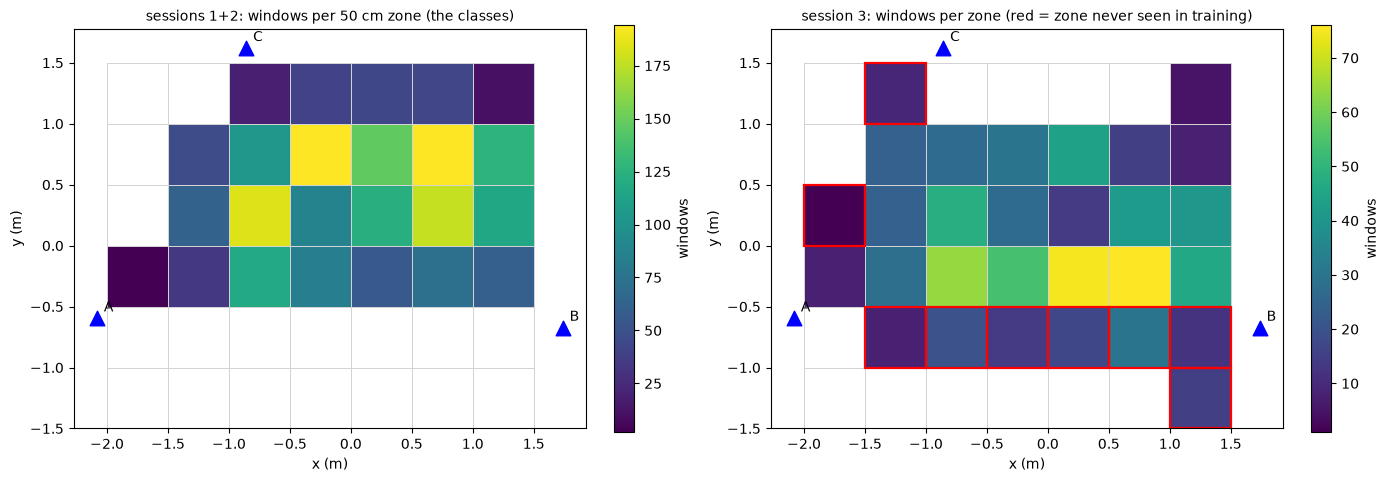

In [7]:
def zone_keys(xy, zs):    return np.floor(xy / zs + 1e-9).astype(int)                # (n, 2) integer cell indices
def zone_center(keys, zs): return (keys + 0.5) * zs                                    # (n, 2) meters

def make_classes(idx, zs):
    # the zones seen in these windows, and how many windows each has
    return np.unique(zone_keys(Y[idx], zs), axis=0, return_counts=True)

def labels_for(idx, classes, zs):
    # class index of each window's zone, or -1 if that zone is not among the classes
    d = {tuple(k): i for i, k in enumerate(classes)}
    return np.array([d.get(tuple(k), -1) for k in zone_keys(Y[idx], zs)])

def zone_metrics(probs, classes, idx, zs):
    keys = zone_keys(Y[idx], zs); lab = labels_for(idx, classes, zs)
    order = np.argsort(-probs, axis=1); pred = order[:, 0]; pk = classes[pred]
    top1 = pred == lab; seen = lab >= 0
    dist = np.linalg.norm(zone_center(pk, zs) - Y[idx], axis=1) * 100
    return dict(top1=float(top1.mean()), top3=float((order[:, :3] == lab[:, None]).any(1).mean()),
                within1=float((np.abs(pk - keys).max(1) <= 1).mean()), median_dist_cm=float(np.median(dist)), mean_dist_cm=float(dist.mean()), p90_dist_cm=float(np.percentile(dist, 90)),
                seen=float(seen.mean()), top1_seen=float(top1[seen].mean()) if seen.any() else float("nan"),
                pred_keys=pk, correct=top1, dist=dist, true_keys=keys, seen_mask=seen)

def extent(zs):
    k = np.concatenate([zone_keys(Y[fit_idx], zs), zone_keys(Y[te_idx], zs)])
    return k.min(0), k.max(0)

def grid_counts(idx, zs):
    lo_, hi_ = extent(zs); g = np.zeros((hi_[1] - lo_[1] + 1, hi_[0] - lo_[0] + 1))
    for kx, ky in zone_keys(Y[idx], zs): g[ky - lo_[1], kx - lo_[0]] += 1
    return g

def draw_grid(ax, zs, values, cmap, title, label, vmin=None, vmax=None, unseen=None):
    lo_, hi_ = extent(zs)
    xe, ye = np.arange(lo_[0], hi_[0] + 2) * zs, np.arange(lo_[1], hi_[1] + 2) * zs
    m = ax.pcolormesh(xe, ye, np.ma.masked_invalid(values), cmap=cmap, vmin=vmin, vmax=vmax, edgecolors="lightgray", linewidth=0.4)
    if unseen is not None:
        for kx, ky in unseen: ax.add_patch(plt.Rectangle((kx * zs, ky * zs), zs, zs, fill=False, ec="red", lw=1.6))
    for ph, (px, py) in ds.phones.items():
        ax.scatter(px, py, marker="^", s=110, c="b", zorder=5); ax.annotate(ph, (px, py), xytext=(5, 5), textcoords="offset points")
    ax.set_aspect("equal"); ax.set_title(title, fontsize=10); ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); plt.colorbar(m, ax=ax, label=label, fraction=0.04)

cfit, cnt_fit = make_classes(fit_idx, ZONE)
unseen_keys = [tuple(k) for k in np.unique(zone_keys(Y[te_idx], ZONE), axis=0) if tuple(k) not in {tuple(c) for c in cfit}]
lab_te = labels_for(te_idx, cfit, ZONE)
print(f"zone size {ZONE * 100:.0f} cm: {len(cfit)} zones seen in sessions 1+2 (final fit), median {int(np.median(cnt_fit))} windows per zone, min {cnt_fit.min()}")
print(f"session 3: {len(np.unique(zone_keys(Y[te_idx], ZONE), axis=0))} zones visited, {len(unseen_keys)} of them never seen in training; "
      f"{(lab_te < 0).sum()} of {len(te_idx)} test windows ({(lab_te < 0).mean():.0%}) are in unseen zones, so at most {(lab_te >= 0).mean():.0%} accuracy is reachable")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
g_tr = grid_counts(fit_idx, ZONE); g_te = grid_counts(te_idx, ZONE)
draw_grid(ax[0], ZONE, np.where(g_tr > 0, g_tr, np.nan), "viridis", f"sessions 1+2: windows per {ZONE * 100:.0f} cm zone (the classes)", "windows")
draw_grid(ax[1], ZONE, np.where(g_te > 0, g_te, np.nan), "viridis", "session 3: windows per zone (red = zone never seen in training)", "windows", unseen=unseen_keys)
plt.tight_layout()


## Training and evaluating a classifier
`fit_cls` trains a **fresh** network from scratch for a given number of epochs with the distance-aware loss described at the top (expected distance to the zone centres plus 0.1 x cross-entropy; standardisation from the training windows only; the raw-audio network gets the same random +-6 dB common gain as before) and returns the probability of every zone. `run_model` does the whole protocol for one model: two seeds on the 80% part to find the epoch count with the lowest **validation mean distance** (smoothed over epochs), a validation score from models trained on the 80% part, then a **final fit on all of sessions 1 and 2** (5 seeds for the MLP, 3 for the CNNs, probabilities averaged), the test score on session 3, and saving.


In [8]:

import json
W_CE = 0.1            # weight of the cross-entropy term next to the expected-distance term

def fit_cls(kind, make_net, Xa, la, Xb, epochs, seed, pos_a, centers, zs, lb=None, pos_b=None, keep=None):
    # trains a fresh classifier with  loss = expected distance (in cells) + W_CE * cross-entropy.
    # returns the zone probabilities for Xb after `epochs` and, if lb/pos_b are given, the validation curves per epoch
    Xa = Xa.astype(np.float32); Xb = Xb.astype(np.float32)
    if kind == "flat":
        mu, sd = Xa.mean(0), Xa.std(0) + 1e-6; info = (mu, sd); bs, Opt, lr = 128, torch.optim.Adam, 3e-3
        norm = lambda x: (x - torch.tensor(mu)) / torch.tensor(sd)
    elif kind == "spec":
        mu, sd = Xa.mean((0, 3), keepdims=True), Xa.std((0, 3), keepdims=True) + 1e-6; info = (mu, sd); bs, Opt, lr = 64, torch.optim.AdamW, 2e-3
        norm = lambda x: (x - torch.tensor(mu)) / torch.tensor(sd)
    else:
        sd = float(Xa.std()); info = (sd,); bs, Opt, lr = 64, torch.optim.AdamW, 2e-3
        norm = lambda x: x / sd
    xa, xb, la_t = torch.tensor(Xa), torch.tensor(Xb), torch.tensor(la)
    cen = torch.tensor(centers, dtype=torch.float32)
    Da = torch.cdist(torch.tensor(pos_a, dtype=torch.float32), cen) / zs          # (windows, zones): distance of the speaker to every zone centre, in cells
    torch.manual_seed(seed); net = make_net()
    opt = Opt(net.parameters(), lr=lr, weight_decay=1e-3)
    def predict():
        net.eval()
        with torch.no_grad():
            return torch.cat([F.softmax(net(norm(xb[i:i + 256])), 1) for i in range(0, len(xb), 256)]).numpy()
    acc, ce, dist = [], [], []
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(xa))
        for s0 in range(0, len(xa), bs):
            b = perm[s0:s0 + bs]
            if len(b) < 2: continue
            xbatch = xa[b]
            if kind == "raw": xbatch = xbatch * (10 ** (torch.empty(len(b), 1, 1).uniform_(-6, 6) / 20))
            logits = net(norm(xbatch)); p = F.softmax(logits, 1)
            loss = (p * Da[b]).sum(1).mean() + W_CE * F.cross_entropy(logits, la_t[b])
            opt.zero_grad(); loss.backward(); opt.step()
        if lb is not None:
            p = predict(); seen = lb >= 0
            acc.append(float((p.argmax(1) == lb).mean())); ce.append(float(-np.log(p[seen, lb[seen]] + 1e-9).mean()))
            dist.append(float(np.linalg.norm(centers[p.argmax(1)] - pos_b, axis=1).mean() * 100))
    if keep is not None:
        keep.append(dict(state={k: v.detach().clone() for k, v in net.state_dict().items()}, norm=info))
    return predict(), dict(acc=acc, ce=ce, dist=dist)

RESULTS_JSON = SAVE_DIR / "results_zones.json"
all_results = {}
def scalar(m): return {k: v for k, v in m.items() if isinstance(v, float)}

def run_model(name, kind, builder, X, max_epochs, zs, final_seeds, smooth_k, save=True):
    ctr, _ = make_classes(tr_idx, zs); la, lb = labels_for(tr_idx, ctr, zs), labels_for(va_idx, ctr, zs)
    cen_tr = zone_center(ctr, zs)
    nparams = sum(p.numel() for p in builder(len(ctr)).parameters())
    print(f"{name}, zone {zs * 100:.0f} cm: {len(ctr)} classes in training, {nparams:,} parameters, {X[0].size:,} numbers per window")
    curves = [fit_cls(kind, lambda: builder(len(ctr)), X[tr_idx], la, X[va_idx], max_epochs, sd, Y[tr_idx], cen_tr, zs, lb, Y[va_idx])[1] for sd in (0, 1)]
    acc, dist = np.mean([c["acc"] for c in curves], 0), np.mean([c["dist"] for c in curves], 0)
    g = int(np.argmin(np.convolve(dist, np.ones(smooth_k) / smooth_k, "valid"))) + smooth_k // 2 + 1      # epoch count with the lowest validation distance
    g = min(g, max_epochs)
    pv = np.mean([fit_cls(kind, lambda: builder(len(ctr)), X[tr_idx], la, X[va_idx], g, sd, Y[tr_idx], cen_tr, zs)[0] for sd in range(final_seeds)], axis=0)
    cf, _ = make_classes(fit_idx, zs); lf = labels_for(fit_idx, cf, zs); kp = []; cen_f = zone_center(cf, zs)
    pt = np.mean([fit_cls(kind, lambda: builder(len(cf)), X[fit_idx], lf, X[te_idx], g, sd, Y[fit_idx], cen_f, zs, keep=kp)[0] for sd in range(final_seeds)], axis=0)
    mv, mt = zone_metrics(pv, ctr, va_idx, zs), zone_metrics(pt, cf, te_idx, zs)
    r = dict(name=name, zs=zs, epochs=g, classes_tr=ctr, classes_fit=cf, val=mv, test=mt, probs_val=pv, probs_test=pt, acc_curve=acc, dist_curve=dist, params=nparams)
    print(f"   epochs={g}   validation: median distance {mv['median_dist_cm']:.0f} cm (mean {mv['mean_dist_cm']:.0f}), top-1 {mv['top1']:.0%}, within 1 cell {mv['within1']:.0%}"
          f"   |   test: median distance {mt['median_dist_cm']:.0f} cm (mean {mt['mean_dist_cm']:.0f}, p90 {mt['p90_dist_cm']:.0f}), top-1 {mt['top1']:.0%} (seen zones {mt['top1_seen']:.0%}), top-3 {mt['top3']:.0%}, within 1 cell {mt['within1']:.0%}")
    tag = f"{name.replace(' ', '_').replace('-', '')}_zone{int(round(zs * 100))}cm"
    if save:
        torch.save(dict(name=name, zone_size_m=zs, classes=cf, epochs=g, members=kp, params=nparams, loss="expected distance + %.1f cross-entropy" % W_CE, val=scalar(mv), test=scalar(mt)), SAVE_DIR / f"{tag}.pt")
        np.savez_compressed(SAVE_DIR / f"{tag}_probs.npz", probs_val=pv, probs_test=pt, classes_tr=ctr, classes_fit=cf, val_idx=va_idx, test_idx=te_idx)
        all_results[tag] = dict(name=name, zone_size_m=zs, epochs=g, params=nparams, classes=len(cf), val=scalar(mv), test=scalar(mt))
        json.dump(all_results, open(RESULTS_JSON, "w"), indent=1)
        print(f"   saved {tag}.pt, {tag}_probs.npz and updated {RESULTS_JSON.name}")
    return r


## Rough-guess baselines
Two guesses that ignore the audio, both using only how often each zone occurred in sessions 1 and 2:
* **Majority zone**: always answer the most common zone. (The analogue of the mean-position baseline.)
* **Random guess from the prior**: answer a random zone drawn with the training frequencies, as someone who knows the route but hears nothing. Its exact-match and within-one-cell scores are computed as expectations; its distance by 200 random draws.

For reference the uniform chance level is one over the number of zones.

In [9]:
def baselines(zs):
    cf, cnt = make_classes(fit_idx, zs); prior = cnt / cnt.sum()
    maj = zone_metrics(np.tile(prior, (len(te_idx), 1)), cf, te_idx, zs)                   # argmax of the prior = the majority zone
    ctr, cnt_tr = make_classes(tr_idx, zs)
    maj_val = zone_metrics(np.tile(cnt_tr / cnt_tr.sum(), (len(va_idx), 1)), ctr, va_idx, zs)
    kt = zone_keys(Y[te_idx], zs); d = np.abs(cf[None, :, :] - kt[:, None, :]).max(2)       # cell distance of every test window to every class
    rng = np.random.default_rng(0); draws = rng.choice(len(cf), size=(200, len(te_idx)), p=prior)
    dist = np.linalg.norm(zone_center(cf[draws], zs) - Y[te_idx], axis=2) * 100
    return dict(majority=maj, majority_val=maj_val, prior_top1=float(((d == 0) * prior).sum(1).mean()), prior_within1=float(((d <= 1) * prior).sum(1).mean()),
                prior_median_dist_cm=float(np.mean(np.median(dist, 1))), uniform=1 / len(cf), n_classes=len(cf))

base = baselines(ZONE); bm = base["majority"]
print(f"zone size {ZONE * 100:.0f} cm, {base['n_classes']} classes (uniform chance {base['uniform']:.1%})")
print(f"majority zone:        test top-1 {bm['top1']:.1%}, within 1 cell {bm['within1']:.0%}, median distance {bm['median_dist_cm']:.0f} cm   (validation top-1 {base['majority_val']['top1']:.1%})")
print(f"random guess (prior): test top-1 {base['prior_top1']:.1%}, within 1 cell {base['prior_within1']:.0%}, median distance {base['prior_median_dist_cm']:.0f} cm")
all_results["baselines_50cm"] = dict(zone_size_m=ZONE, classes=base["n_classes"], majority_test=scalar(bm), majority_val=scalar(base["majority_val"]),
                                      prior=dict(top1=base["prior_top1"], within1=base["prior_within1"], median_dist_cm=base["prior_median_dist_cm"]), uniform=base["uniform"])
json.dump(all_results, open(RESULTS_JSON, "w"), indent=1)

zone size 50 cm, 24 classes (uniform chance 4.2%)
majority zone:        test top-1 3.6%, within 1 cell 23%, median distance 118 cm   (validation top-1 6.1%)
random guess (prior): test top-1 4.1%, within 1 cell 29%, median distance 119 cm


## The three models at the main zone size (weights and predictions are saved as each one finishes)

In [10]:
res = {}
res["8-band MLP"] = run_model("8-band MLP", "flat", lambda k: make_mlp_cls(X_band.shape[1], k), X_band, MAXE["mlp"], ZONE, 5, 5)

8-band MLP, zone 50 cm: 24 classes in training, 7,320 parameters, 24 numbers per window


   epochs=13   validation: median distance 43 cm (mean 53), top-1 29%, within 1 cell 81%   |   test: median distance 61 cm (mean 72, p90 142), top-1 19% (seen zones 23%), top-3 43%, within 1 cell 68%
   saved 8band_MLP_zone50cm.pt, 8band_MLP_zone50cm_probs.npz and updated results_zones.json


In [11]:
res["log-mel CNN"] = run_model("log-mel CNN", "spec", make_spec_cnn, S, MAXE["spec"], ZONE, 3, 3)

log-mel CNN, zone 50 cm: 24 classes in training, 9,240 parameters, 9,696 numbers per window


   epochs=54   validation: median distance 37 cm (mean 49), top-1 32%, within 1 cell 85%   |   test: median distance 50 cm (mean 61, p90 126), top-1 23% (seen zones 28%), top-3 53%, within 1 cell 77%
   saved logmel_CNN_zone50cm.pt, logmel_CNN_zone50cm_probs.npz and updated results_zones.json


In [12]:
res["raw-audio CNN"] = run_model("raw-audio CNN", "raw", make_raw_cnn, X_raw, MAXE["raw"], ZONE, 3, 3)

raw-audio CNN, zone 50 cm: 24 classes in training, 11,736 parameters, 48,000 numbers per window


   epochs=25   validation: median distance 59 cm (mean 68), top-1 14%, within 1 cell 70%   |   test: median distance 81 cm (mean 86, p90 149), top-1 8% (seen zones 10%), top-3 24%, within 1 cell 52%
   saved rawaudio_CNN_zone50cm.pt, rawaudio_CNN_zone50cm_probs.npz and updated results_zones.json


## Zone-size sweep (cheap models only)
The baselines and the 8-band MLP at several zone sizes, everything else unchanged. Smaller cells are harder to get exactly right and have more classes with fewer windows each; larger cells are easier but say less about where the speaker is.

In [13]:
sweep = {}
for zs in ZONE_SWEEP:
    b = baselines(zs)
    r = res["8-band MLP"] if zs == ZONE else run_model("8-band MLP", "flat", lambda k: make_mlp_cls(X_band.shape[1], k), X_band, MAXE["mlp"], zs, 5, 5)
    sweep[zs] = dict(base=b, mlp=r)

8-band MLP, zone 25 cm: 75 classes in training, 10,635 parameters, 24 numbers per window


   epochs=31   validation: median distance 36 cm (mean 51), top-1 15%, within 1 cell 56%   |   test: median distance 58 cm (mean 69, p90 136), top-1 6% (seen zones 8%), top-3 15%, within 1 cell 36%
   saved 8band_MLP_zone25cm.pt, 8band_MLP_zone25cm_probs.npz and updated results_zones.json
8-band MLP, zone 75 cm: 13 classes in training, 6,605 parameters, 24 numbers per window


   epochs=20   validation: median distance 46 cm (mean 54), top-1 44%, within 1 cell 95%   |   test: median distance 67 cm (mean 76, p90 146), top-1 25% (seen zones 26%), top-3 59%, within 1 cell 85%
   saved 8band_MLP_zone75cm.pt, 8band_MLP_zone75cm_probs.npz and updated results_zones.json
8-band MLP, zone 100 cm: 11 classes in training, 6,475 parameters, 24 numbers per window


   epochs=9   validation: median distance 53 cm (mean 57), top-1 55%, within 1 cell 97%   |   test: median distance 79 cm (mean 86, p90 162), top-1 30% (seen zones 31%), top-3 68%, within 1 cell 91%
   saved 8band_MLP_zone100cm.pt, 8band_MLP_zone100cm_probs.npz and updated results_zones.json


  zone  classes  majority   prior  MLP top-1  MLP seen-only  within 1  distance cm  reachable
   25c       76      0.7%    1.1%       5.8%           8.1%       36%           58        71%
   50c       24      3.6%    4.1%      19.2%          22.7%       68%           61        85%
   75c       13     10.3%    7.8%      24.8%          25.6%       85%           67        97%
  100c       11     13.9%   12.8%      30.3%          31.2%       91%           79        97%


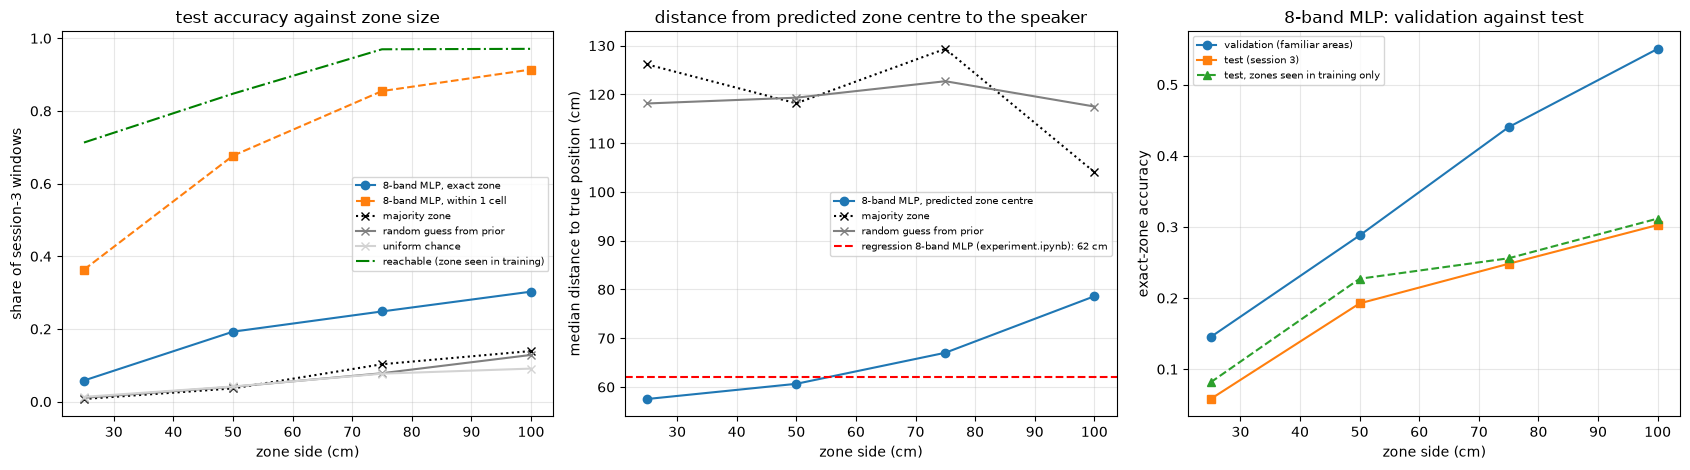

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
zs_list = sorted(sweep); xs = [z * 100 for z in zs_list]
for key, lab, st in (("top1", "8-band MLP, exact zone", "o-"), ("within1", "8-band MLP, within 1 cell", "s--")):
    ax[0].plot(xs, [sweep[z]["mlp"]["test"][key] for z in zs_list], st, label=lab)
ax[0].plot(xs, [sweep[z]["base"]["majority"]["top1"] for z in zs_list], "k:", marker="x", label="majority zone")
ax[0].plot(xs, [sweep[z]["base"]["prior_top1"] for z in zs_list], "-", c="gray", marker="x", label="random guess from prior")
ax[0].plot(xs, [sweep[z]["base"]["uniform"] for z in zs_list], "-", c="lightgray", marker="x", label="uniform chance")
ax[0].plot(xs, [sweep[z]["mlp"]["test"]["seen"] for z in zs_list], "g-.", label="reachable (zone seen in training)")
ax[0].set_xlabel("zone side (cm)"); ax[0].set_ylabel("share of session-3 windows"); ax[0].set_title("test accuracy against zone size"); ax[0].legend(fontsize=7); ax[0].grid(alpha=0.3)
ax[1].plot(xs, [sweep[z]["mlp"]["test"]["median_dist_cm"] for z in zs_list], "o-", label="8-band MLP, predicted zone centre")
ax[1].plot(xs, [sweep[z]["base"]["majority"]["median_dist_cm"] for z in zs_list], "k:", marker="x", label="majority zone")
ax[1].plot(xs, [sweep[z]["base"]["prior_median_dist_cm"] for z in zs_list], "-", c="gray", marker="x", label="random guess from prior")
reg = json.load(open("trained_models/summary.json"))["models"]["8-band_mlp"]["test_median_cm"]
ax[1].axhline(reg, c="r", ls="--", label=f"regression 8-band MLP (experiment.ipynb): {reg:.0f} cm")
ax[1].set_xlabel("zone side (cm)"); ax[1].set_ylabel("median distance to true position (cm)"); ax[1].set_title("distance from predicted zone centre to the speaker"); ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3)
ax[2].plot(xs, [sweep[z]["mlp"]["val"]["top1"] for z in zs_list], "o-", label="validation (familiar areas)")
ax[2].plot(xs, [sweep[z]["mlp"]["test"]["top1"] for z in zs_list], "s-", label="test (session 3)")
ax[2].plot(xs, [sweep[z]["mlp"]["test"]["top1_seen"] for z in zs_list], "^--", label="test, zones seen in training only")
ax[2].set_xlabel("zone side (cm)"); ax[2].set_ylabel("exact-zone accuracy"); ax[2].set_title("8-band MLP: validation against test"); ax[2].legend(fontsize=7); ax[2].grid(alpha=0.3)
plt.tight_layout()
print(f"{'zone':>6}{'classes':>9}{'majority':>10}{'prior':>8}{'MLP top-1':>11}{'MLP seen-only':>15}{'within 1':>10}{'distance cm':>13}{'reachable':>11}")
for z in zs_list:
    m = sweep[z]["mlp"]["test"]; b = sweep[z]["base"]
    print(f"{z * 100:5.0f}c{b['n_classes']:9}{b['majority']['top1']:10.1%}{b['prior_top1']:8.1%}{m['top1']:11.1%}{m['top1_seen']:15.1%}{m['within1']:10.0%}{m['median_dist_cm']:13.0f}{m['seen']:11.0%}")

## Results at the main zone size (50 cm)

In [15]:

names = ["8-band MLP", "log-mel CNN", "raw-audio CNN"]
print(f"{'':<22}{'val mean dist':>14}{'test median':>12}{'test mean':>10}{'test p90':>9}{'top-1':>7}{'seen-only':>10}{'top-3':>7}{'within 1':>9}{'epochs':>8}{'params':>9}   (distances in cm)")
print(f"{'majority zone':<22}{base['majority_val']['mean_dist_cm']:14.0f}{bm['median_dist_cm']:12.0f}{bm['mean_dist_cm']:10.0f}{bm['p90_dist_cm']:9.0f}{bm['top1']:7.1%}{bm['top1_seen']:10.1%}{bm['top3']:7.0%}{bm['within1']:9.0%}")
print(f"{'random guess (prior)':<22}{'':>14}{base['prior_median_dist_cm']:12.0f}{'':>10}{'':>9}{base['prior_top1']:7.1%}{'':>10}{'':>7}{base['prior_within1']:9.0%}")
for n in sorted(names, key=lambda k: res[k]["val"]["mean_dist_cm"]):
    r = res[n]; m = r["test"]
    print(f"{n:<22}{r['val']['mean_dist_cm']:14.0f}{m['median_dist_cm']:12.0f}{m['mean_dist_cm']:10.0f}{m['p90_dist_cm']:9.0f}{m['top1']:7.1%}{m['top1_seen']:10.1%}{m['top3']:7.0%}{m['within1']:9.0%}{r['epochs']:8}{r['params']:9,}")
headline = min(names, key=lambda k: res[k]["val"]["mean_dist_cm"])
print("\nheadline (lowest validation mean distance):", headline)
print(f"reachable share of the test (zone seen in training): {res[headline]['test']['seen']:.0%}")


                       val mean dist test median test mean test p90  top-1 seen-only  top-3 within 1  epochs   params   (distances in cm)
majority zone                     87         118       116      167   3.6%      4.3%    11%      23%
random guess (prior)                         119                      4.1%                       29%
log-mel CNN                       49          50        61      126  23.5%     27.7%    53%      77%      54    9,240
8-band MLP                        53          61        72      142  19.2%     22.7%    43%      68%      13    7,320
raw-audio CNN                     68          81        86      149   8.5%     10.0%    24%      52%      25   11,736

headline (lowest validation mean distance): log-mel CNN
reachable share of the test (zone seen in training): 85%


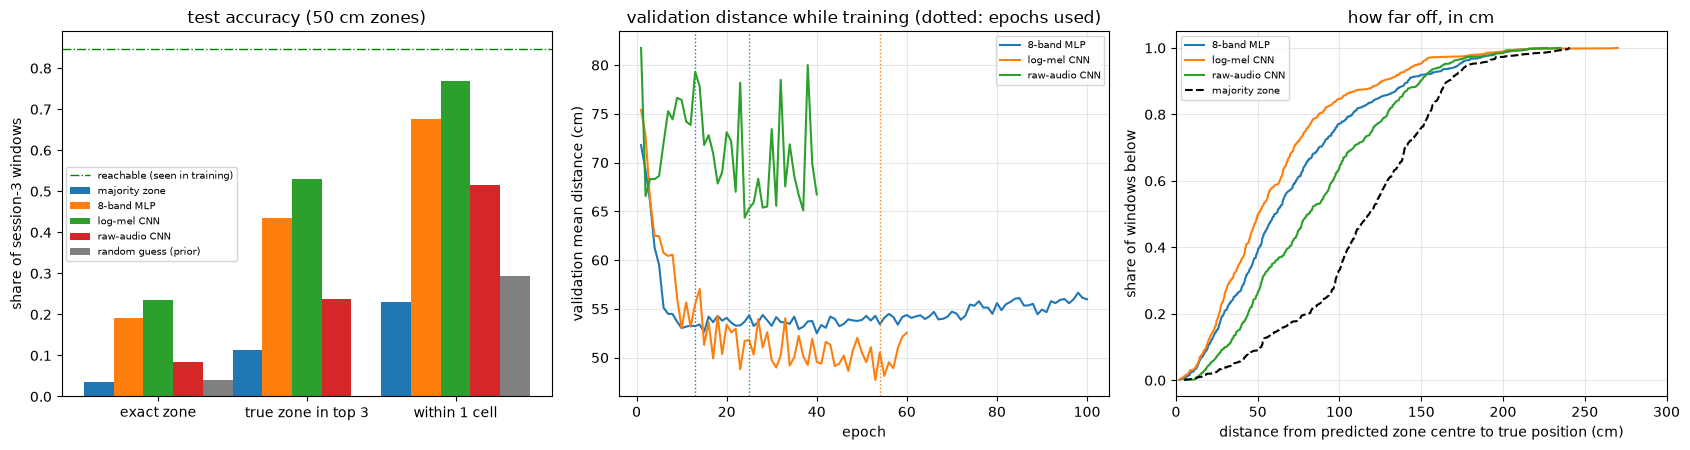

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
rows = [("majority zone", bm), ("8-band MLP", res["8-band MLP"]["test"]), ("log-mel CNN", res["log-mel CNN"]["test"]), ("raw-audio CNN", res["raw-audio CNN"]["test"])]
w = 0.2; xs_ = np.arange(3)
for j, (lab, m) in enumerate(rows):
    ax[0].bar(xs_ + j * w, [m["top1"], m["top3"], m["within1"]], w, label=lab)
ax[0].bar(xs_[0] + 4 * w, base["prior_top1"], w, color="gray", label="random guess (prior)"); ax[0].bar(xs_[2] + 4 * w, base["prior_within1"], w, color="gray")
ax[0].axhline(res[headline]["test"]["seen"], c="g", ls="-.", lw=1, label="reachable (seen in training)")
ax[0].set_xticks(xs_ + 2 * w); ax[0].set_xticklabels(["exact zone", "true zone in top 3", "within 1 cell"]); ax[0].set_ylabel("share of session-3 windows"); ax[0].legend(fontsize=7); ax[0].set_title("test accuracy (50 cm zones)")
for n in names:
    ax[1].plot(np.arange(1, len(res[n]["dist_curve"]) + 1), res[n]["dist_curve"], label=n)
    ax[1].axvline(res[n]["epochs"], c=ax[1].lines[-1].get_color(), ls=":", lw=1)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation mean distance (cm)"); ax[1].set_title("validation distance while training (dotted: epochs used)"); ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3)
for n in names:
    e = np.sort(res[n]["test"]["dist"]); ax[2].plot(e, np.arange(1, len(e) + 1) / len(e), label=n)
e = np.sort(bm["dist"]); ax[2].plot(e, np.arange(1, len(e) + 1) / len(e), "k--", label="majority zone")
ax[2].set_xlim(0, 300); ax[2].set_xlabel("distance from predicted zone centre to true position (cm)"); ax[2].set_ylabel("share of windows below"); ax[2].legend(fontsize=7); ax[2].grid(alpha=0.3); ax[2].set_title("how far off, in cm")
plt.tight_layout()

### Per model: where it is right, and the track
Left: for each zone, the share of the session-3 windows in it that the model got right (white = no windows; red outline = zone never seen in training, so unreachable). Right: session 3's true track (black) against the **centres of the predicted zones** (red dots and thin line, one per window; green = the answer was exactly right).

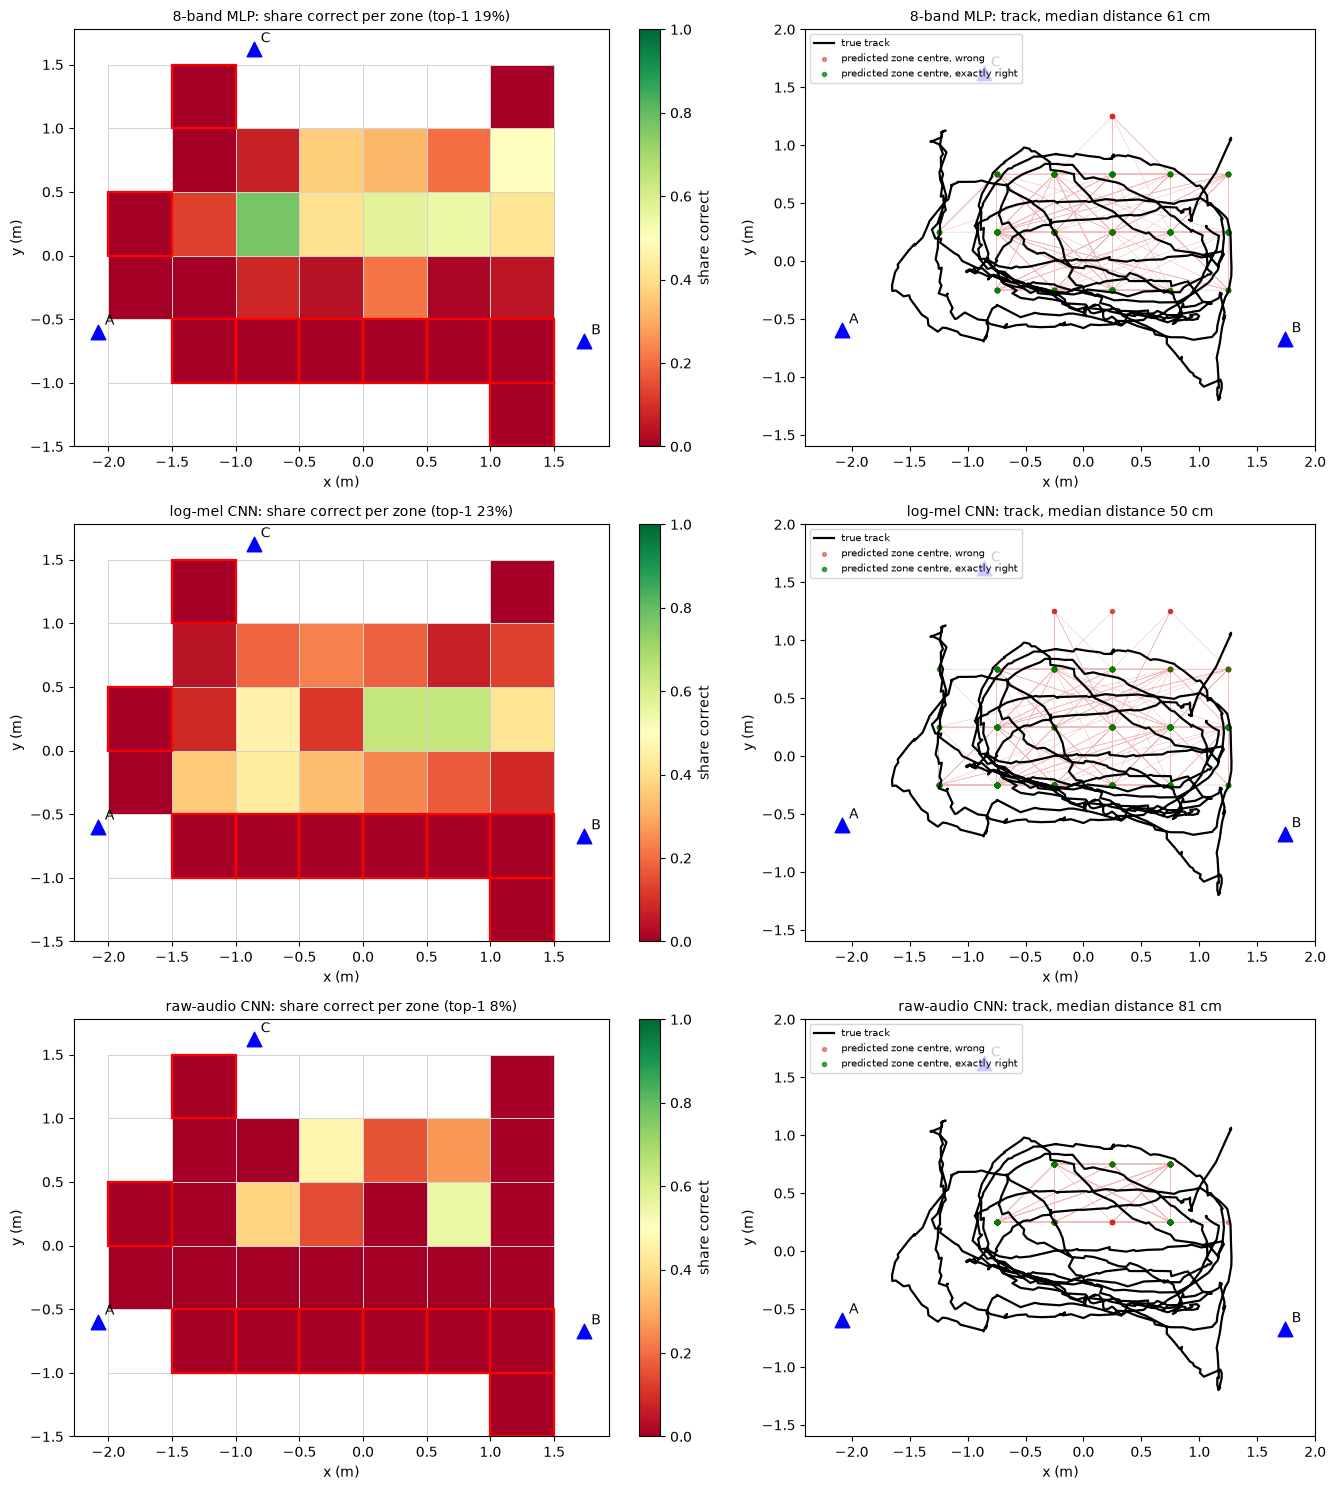

In [17]:
fig, ax = plt.subplots(3, 2, figsize=(14, 15))
for row, n in zip(ax, names):
    t = res[n]["test"]; lo_, hi_ = extent(ZONE)
    g_ok = np.zeros((hi_[1] - lo_[1] + 1, hi_[0] - lo_[0] + 1)); g_n = np.zeros_like(g_ok)
    for (kx, ky), ok in zip(t["true_keys"], t["correct"]):
        g_n[ky - lo_[1], kx - lo_[0]] += 1; g_ok[ky - lo_[1], kx - lo_[0]] += ok
    draw_grid(row[0], ZONE, np.where(g_n > 0, g_ok / np.maximum(g_n, 1), np.nan), "RdYlGn", f"{n}: share correct per zone (top-1 {t['top1']:.0%})", "share correct", 0, 1, unseen_keys)
    pc = zone_center(t["pred_keys"], ZONE)
    row[1].plot(*Y[te_idx].T, "k-", lw=1.6, label="true track", zorder=3)
    row[1].plot(*pc.T, "-", c="tab:red", lw=0.4, alpha=0.3, zorder=1)
    row[1].scatter(*pc[~t["correct"]].T, s=8, c="tab:red", alpha=0.5, label="predicted zone centre, wrong", zorder=2)
    row[1].scatter(*pc[t["correct"]].T, s=9, c="green", alpha=0.7, label="predicted zone centre, exactly right", zorder=2)
    for ph, (px, py) in ds.phones.items():
        row[1].scatter(px, py, marker="^", s=110, c="b", zorder=5); row[1].annotate(ph, (px, py), xytext=(5, 5), textcoords="offset points")
    row[1].set_aspect("equal"); row[1].set_xlim(-2.4, 2.0); row[1].set_ylim(-1.6, 2.0); row[1].legend(fontsize=7, loc="upper left")
    row[1].set_title(f"{n}: track, median distance {t['median_dist_cm']:.0f} cm", fontsize=10); row[1].set_xlabel("x (m)"); row[1].set_ylabel("y (m)")
plt.tight_layout()

### Confusion matrix of the headline model
Rows: the true zone of session-3 windows (only zones seen in training; windows in unseen zones cannot be right and are left out here). Columns: the predicted zone. Each row is normalised to 1 (diagonal = correct); the number in each cell is the count. Zone labels are `(ix, iy)` cell indices, sorted by ix then iy.

of the 700 test windows in seen zones: 28% in the right zone, 57% one cell away, 9% two cells away, 6% three or more


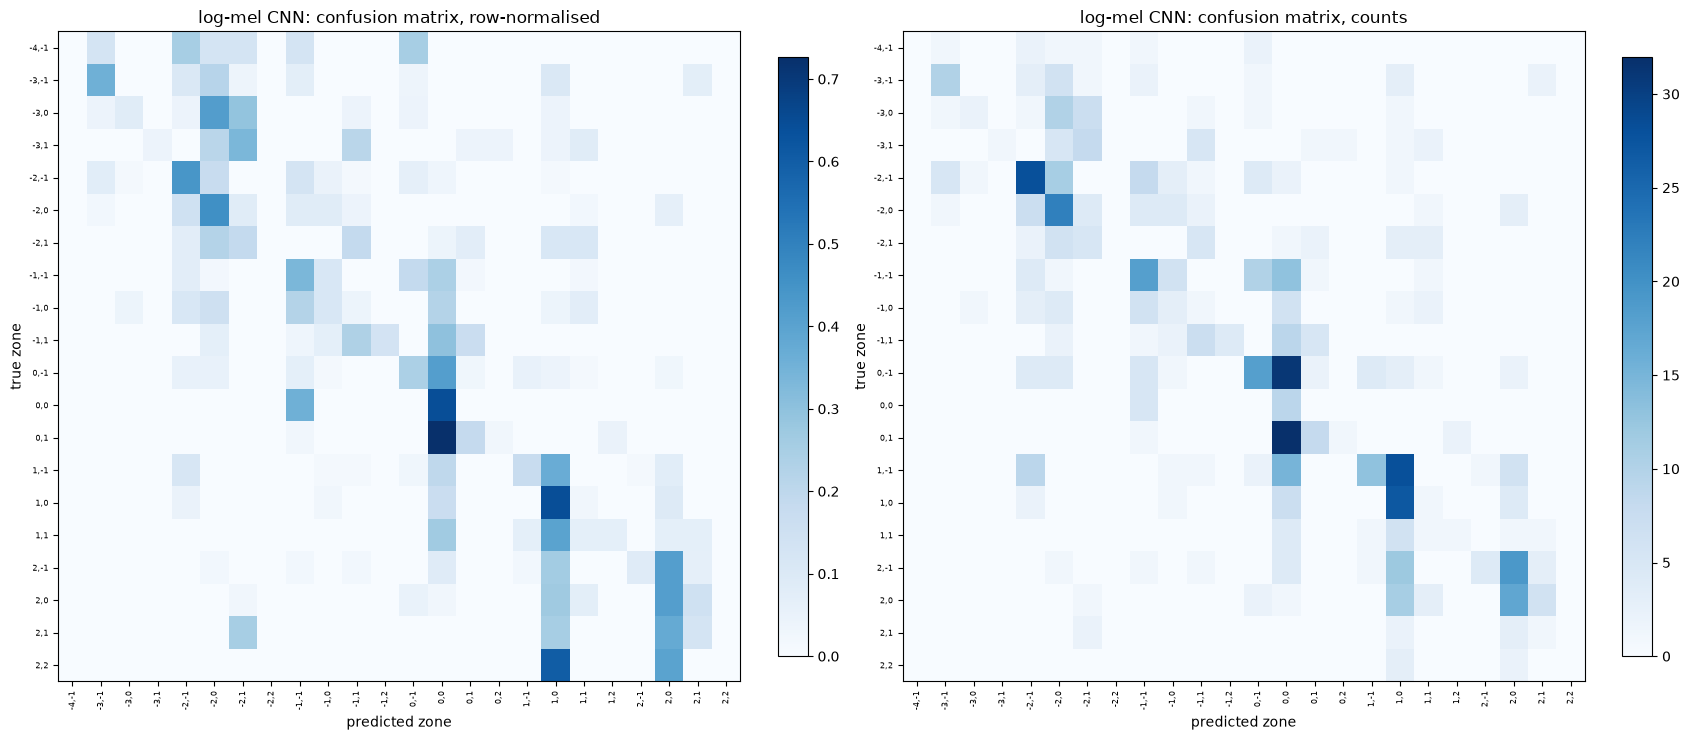

In [18]:
t = res[headline]["test"]; cf = res[headline]["classes_fit"]; K = len(cf)
lab = labels_for(te_idx, cf, ZONE); sel = lab >= 0
pred_idx = np.argmax(res[headline]["probs_test"], axis=1)
cm = np.zeros((K, K), int)
for a, b in zip(lab[sel], pred_idx[sel]): cm[a, b] += 1
rows_used = cm.sum(1) > 0
fig, ax = plt.subplots(1, 2, figsize=(17, 7.5))
for a, (mat, title) in zip(ax, ((cm[rows_used] / np.maximum(cm[rows_used].sum(1, keepdims=True), 1), "row-normalised"), (cm[rows_used], "counts"))):
    im = a.imshow(mat, cmap="Blues", aspect="auto"); plt.colorbar(im, ax=a, fraction=0.04)
    a.set_xticks(range(K)); a.set_xticklabels([f"{k[0]},{k[1]}" for k in cf], rotation=90, fontsize=6)
    a.set_yticks(range(rows_used.sum())); a.set_yticklabels([f"{k[0]},{k[1]}" for k in cf[rows_used]], fontsize=6)
    a.set_xlabel("predicted zone"); a.set_ylabel("true zone"); a.set_title(f"{headline}: confusion matrix, {title}")
plt.tight_layout()
off = np.abs(cf[pred_idx[sel]] - cf[lab[sel]]).max(1)
print(f"of the {sel.sum()} test windows in seen zones: {np.mean(off == 0):.0%} in the right zone, {np.mean(off == 1):.0%} one cell away, {np.mean(off == 2):.0%} two cells away, {np.mean(off >= 3):.0%} three or more")

## Comparison with the cross-entropy run
The same models, zone size, split and test windows, trained once with cross-entropy (`experiment_zones.ipynb`, saved in `trained_models_zones/`) and once with the distance-aware loss. The cross-entropy predictions are read back from the saved probability files, so both are scored by exactly the same code. The two losses also choose their epoch count by different rules (accuracy against distance), as described at the top.

                loss                top-1 within 1 median cm  mean cm  p90 cm
8-band MLP      cross-entropy       21.4%      66%        60       73     147
8-band MLP      expected distance   19.2%      68%        61       72     142
log-mel CNN     cross-entropy       26.8%      74%        49       63     135
log-mel CNN     expected distance   23.5%      77%        50       61     126
raw-audio CNN   cross-entropy       14.8%      58%        69       82     162
raw-audio CNN   expected distance    8.5%      52%        81       86     149


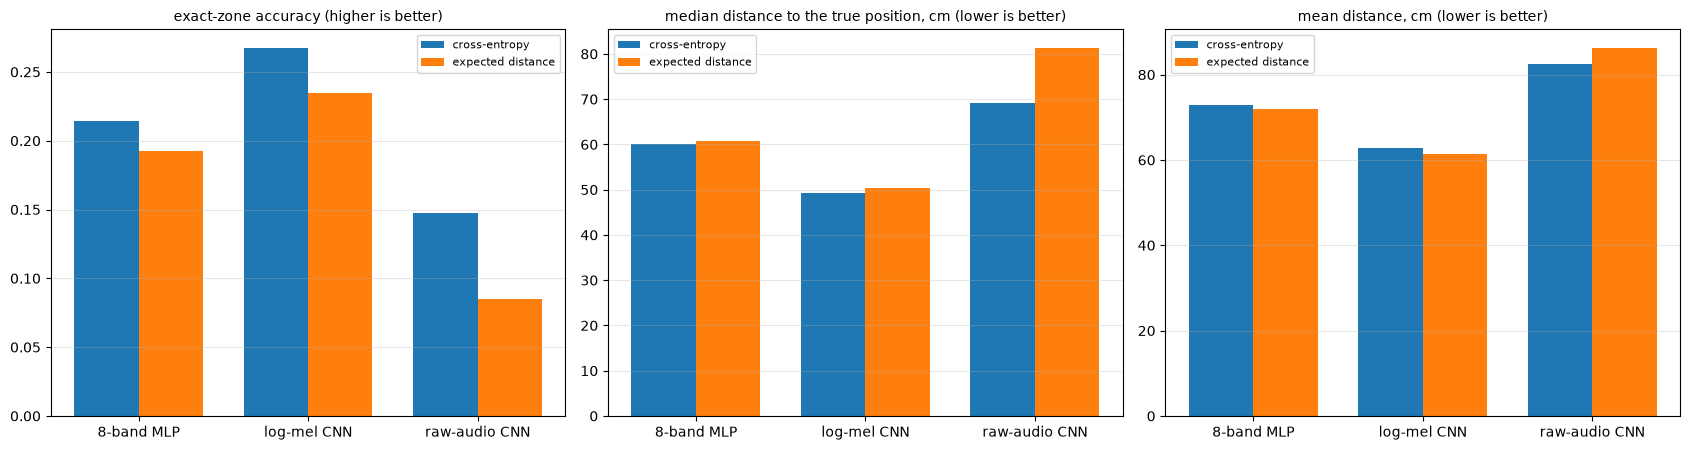

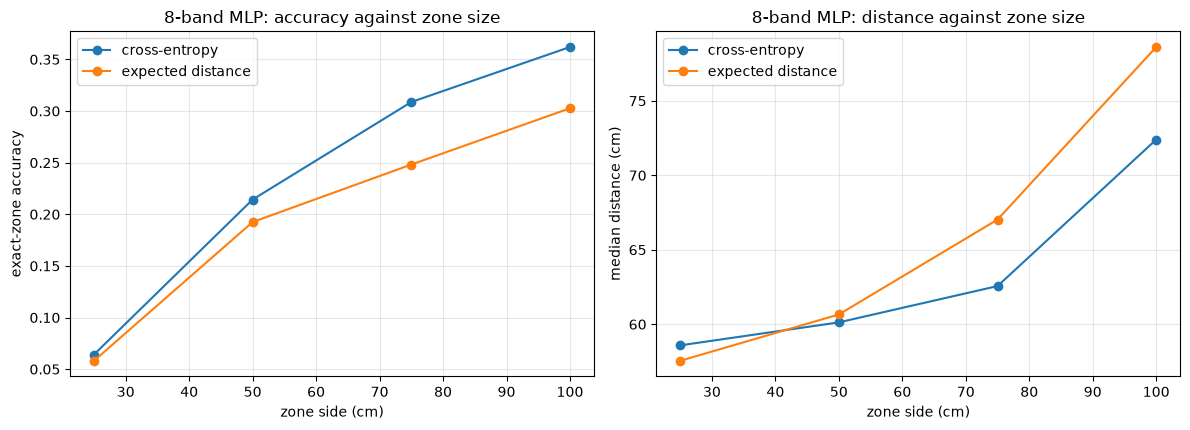

In [19]:
CE_DIR = Path("trained_models_zones")
tags = {"8-band MLP": "8band_MLP", "log-mel CNN": "logmel_CNN", "raw-audio CNN": "rawaudio_CNN"}
def ce_run(tag, zs):
    z = np.load(CE_DIR / f"{tag}_zone{int(round(zs * 100))}cm_probs.npz")
    return zone_metrics(z["probs_test"], z["classes_fit"], te_idx, zs)

rows = {}
print(f"{'':<16}{'loss':<18}{'top-1':>7}{'within 1':>9}{'median cm':>10}{'mean cm':>9}{'p90 cm':>8}")
for n in names:
    for loss_name, m in (("cross-entropy", ce_run(tags[n], ZONE)), ("expected distance", res[n]["test"])):
        rows[(n, loss_name)] = m
        print(f"{n:<16}{loss_name:<18}{m['top1']:7.1%}{m['within1']:9.0%}{m['median_dist_cm']:10.0f}{m['mean_dist_cm']:9.0f}{m['p90_dist_cm']:8.0f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6)); w = 0.38; xs_ = np.arange(3)
for j, loss_name in enumerate(("cross-entropy", "expected distance")):
    ax[0].bar(xs_ + j * w, [rows[(n, loss_name)]["top1"] for n in names], w, label=loss_name)
    ax[1].bar(xs_ + j * w, [rows[(n, loss_name)]["median_dist_cm"] for n in names], w, label=loss_name)
    ax[2].bar(xs_ + j * w, [rows[(n, loss_name)]["mean_dist_cm"] for n in names], w, label=loss_name)
for a, t_ in zip(ax, ("exact-zone accuracy (higher is better)", "median distance to the true position, cm (lower is better)", "mean distance, cm (lower is better)")):
    a.set_xticks(xs_ + w / 2); a.set_xticklabels(names); a.set_title(t_, fontsize=10); a.legend(fontsize=8); a.grid(alpha=0.3, axis="y")
plt.tight_layout()

# the 8-band MLP at every zone size, both losses
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4)); zl = sorted(sweep); xz = [z * 100 for z in zl]
for loss_name, get in (("cross-entropy", lambda z: ce_run("8band_MLP", z)), ("expected distance", lambda z: sweep[z]["mlp"]["test"])):
    ax[0].plot(xz, [get(z)["top1"] for z in zl], "o-", label=loss_name); ax[1].plot(xz, [get(z)["median_dist_cm"] for z in zl], "o-", label=loss_name)
ax[0].set_xlabel("zone side (cm)"); ax[0].set_ylabel("exact-zone accuracy"); ax[0].set_title("8-band MLP: accuracy against zone size"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].set_xlabel("zone side (cm)"); ax[1].set_ylabel("median distance (cm)"); ax[1].set_title("8-band MLP: distance against zone size"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout()

# Second split: train and validate on session 1 only, test on session 2
Everything above trains on sessions 1 **and** 2 and tests on session 3. Here the amount of training data is halved and the test is a different session: **train and validate on session 1 only** (its first 80% of windows in time order to train, the last 20% to validate, training windows within 2 s of the boundary dropped), final fit on **all of session 1**, test once on **session 2**. With roughly 1,000 training windows, a smaller network is the natural thing to try, so:
* **8-band MLP, small:** two hidden layers of **16** units (about 1,100 parameters) instead of 64 (about 7,300), same dropout and weight decay.
* **8-band MLP, standard (64 units)** under the same split, as the reference, so that "smaller" can be judged against "not smaller".
* The **baselines** (majority zone, random guess from the prior), with the zones seen in session 1 as the classes.

Everything else is as in this notebook: the distance-aware loss (expected distance to the zone centres + 0.1 x cross-entropy), 50 cm zones, the epoch count chosen on the validation set by mean distance, five seeds averaged for the final fit. Weights and predictions are saved as each model finishes, with the suffix `_s1to2`, next to the main run's files.

**How to read it.** Sessions 1 and 2 walked mostly the same area (session 2 reaches a few zones session 1 did not), so this tests how well a model carries over to a new recording of familiar ground, not how well it extrapolates; session 3 (above) is the harder test. As before, windows in zones never seen in session 1 cannot be predicted, and one test session is one sample.

train 798  validation 200  (session 1)   final fit 1001 (all of session 1)   test 1136 (session 2)
24 zones seen in session 1; session 2 visits 22 zones, 0 never seen in session 1; 0 of 1136 test windows (0%) are in unseen zones, so at most 100% accuracy is reachable
majority zone:        test top-1 5.8%, within 1 cell 52%, median distance 77 cm   (validation top-1 4.0%)
random guess (prior): test top-1 5.5%, within 1 cell 38%, median distance 103 cm


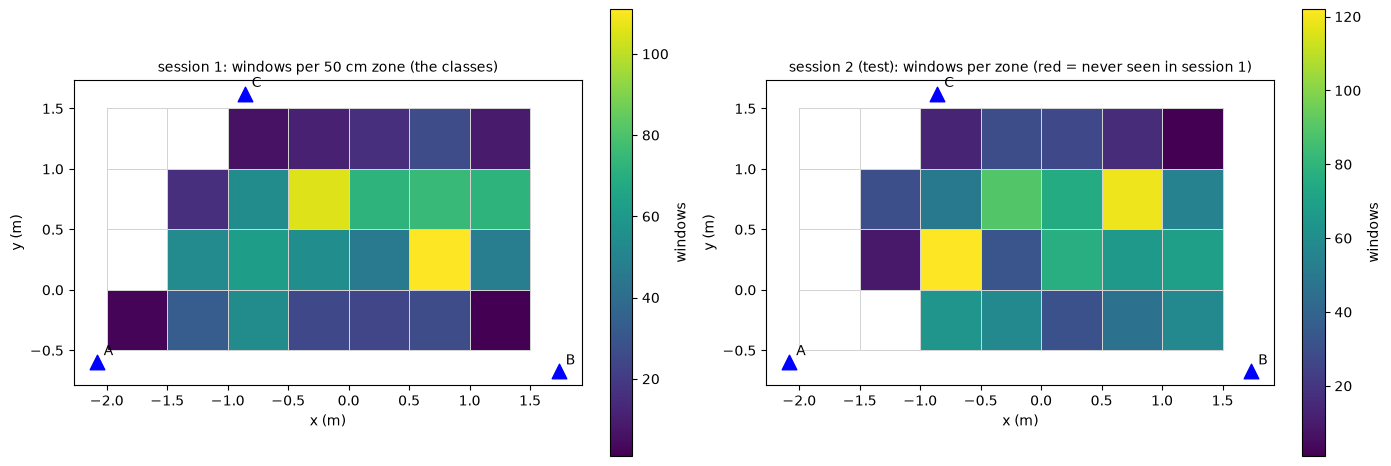

In [20]:
# save the indices used so far, then switch to the session 1 -> session 2 split (restored at the end of this section)
orig_idx = (tr_idx, va_idx, fit_idx, te_idx)
ix1 = np.where(sess == 1)[0]; cut1 = int(round(0.8 * len(ix1))); t_b1 = t_centre[ix1[cut1]]
va_idx = ix1[cut1:]
tr_idx = np.array([i for i in ix1[:cut1] if t_centre[i] <= t_b1 - GAP])
fit_idx, te_idx = ix1, np.where(sess == 2)[0]
print(f"train {len(tr_idx)}  validation {len(va_idx)}  (session 1)   final fit {len(fit_idx)} (all of session 1)   test {len(te_idx)} (session 2)")

cf1, cnt1 = make_classes(fit_idx, ZONE)
seen2 = labels_for(te_idx, cf1, ZONE) >= 0
unseen2 = [tuple(k) for k in np.unique(zone_keys(Y[te_idx], ZONE), axis=0) if tuple(k) not in {tuple(c) for c in cf1}]
print(f"{len(cf1)} zones seen in session 1; session 2 visits {len(np.unique(zone_keys(Y[te_idx], ZONE), axis=0))} zones, {len(unseen2)} never seen in session 1; "
      f"{(~seen2).sum()} of {len(te_idx)} test windows ({(~seen2).mean():.0%}) are in unseen zones, so at most {seen2.mean():.0%} accuracy is reachable")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
g1, g2 = grid_counts(fit_idx, ZONE), grid_counts(te_idx, ZONE)
draw_grid(ax[0], ZONE, np.where(g1 > 0, g1, np.nan), "viridis", "session 1: windows per 50 cm zone (the classes)", "windows")
draw_grid(ax[1], ZONE, np.where(g2 > 0, g2, np.nan), "viridis", "session 2 (test): windows per zone (red = never seen in session 1)", "windows", unseen=unseen2)
plt.tight_layout()
base2 = baselines(ZONE); bm2 = base2["majority"]
print(f"majority zone:        test top-1 {bm2['top1']:.1%}, within 1 cell {bm2['within1']:.0%}, median distance {bm2['median_dist_cm']:.0f} cm   (validation top-1 {base2['majority_val']['top1']:.1%})")
print(f"random guess (prior): test top-1 {base2['prior_top1']:.1%}, within 1 cell {base2['prior_within1']:.0%}, median distance {base2['prior_median_dist_cm']:.0f} cm")

In [21]:
def make_mlp_small(d, k, h=16):
    return nn.Sequential(nn.Linear(d, h), nn.ReLU(), nn.Dropout(0.1), nn.Linear(h, h), nn.ReLU(), nn.Dropout(0.1), nn.Linear(h, k))

def run_model_split(name, tag, kind, builder, X, max_epochs, zs, final_seeds, smooth_k):
    # same protocol as run_model above, on the current (session 1 -> session 2) indices, saving weights and predictions under `tag`
    ctr, _ = make_classes(tr_idx, zs); la, lb = labels_for(tr_idx, ctr, zs), labels_for(va_idx, ctr, zs)
    cen_tr = zone_center(ctr, zs)
    nparams = sum(p.numel() for p in builder(len(ctr)).parameters())
    print(f"{name}: {len(ctr)} classes in training, {nparams:,} parameters, {len(tr_idx)} training windows")
    curves = [fit_cls(kind, lambda: builder(len(ctr)), X[tr_idx], la, X[va_idx], max_epochs, sd, Y[tr_idx], cen_tr, zs, lb, Y[va_idx])[1] for sd in (0, 1)]
    acc, dist = np.mean([c["acc"] for c in curves], 0), np.mean([c["dist"] for c in curves], 0)
    g = min(int(np.argmin(np.convolve(dist, np.ones(smooth_k) / smooth_k, "valid"))) + smooth_k // 2 + 1, max_epochs)
    pv = np.mean([fit_cls(kind, lambda: builder(len(ctr)), X[tr_idx], la, X[va_idx], g, sd, Y[tr_idx], cen_tr, zs)[0] for sd in range(final_seeds)], axis=0)
    cf, _ = make_classes(fit_idx, zs); lf = labels_for(fit_idx, cf, zs); kp = []; cen_f = zone_center(cf, zs)
    pt = np.mean([fit_cls(kind, lambda: builder(len(cf)), X[fit_idx], lf, X[te_idx], g, sd, Y[fit_idx], cen_f, zs, keep=kp)[0] for sd in range(final_seeds)], axis=0)
    mv, mt = zone_metrics(pv, ctr, va_idx, zs), zone_metrics(pt, cf, te_idx, zs)
    r = dict(name=name, epochs=g, classes_tr=ctr, classes_fit=cf, val=mv, test=mt, probs_val=pv, probs_test=pt, acc_curve=acc, dist_curve=dist, params=nparams)
    print(f"   epochs={g}   validation: median distance {mv['median_dist_cm']:.0f} cm (mean {mv['mean_dist_cm']:.0f}), top-1 {mv['top1']:.0%}   |   "
          f"test (session 2): median distance {mt['median_dist_cm']:.0f} cm (mean {mt['mean_dist_cm']:.0f}, p90 {mt['p90_dist_cm']:.0f}), top-1 {mt['top1']:.0%} (seen zones {mt['top1_seen']:.0%}), top-3 {mt['top3']:.0%}, within 1 cell {mt['within1']:.0%}")
    torch.save(dict(name=name, split="train/validate session 1, test session 2", zone_size_m=zs, classes=cf, epochs=g, members=kp, params=nparams,
                    loss="expected distance + %.1f cross-entropy" % W_CE, val=scalar(mv), test=scalar(mt)), SAVE_DIR / f"{tag}.pt")
    np.savez_compressed(SAVE_DIR / f"{tag}_probs.npz", probs_val=pv, probs_test=pt, classes_tr=ctr, classes_fit=cf, val_idx=va_idx, test_idx=te_idx)
    all_results[tag] = dict(name=name, split="session 1 -> session 2", zone_size_m=zs, epochs=g, params=nparams, classes=len(cf), val=scalar(mv), test=scalar(mt))
    json.dump(all_results, open(RESULTS_JSON, "w"), indent=1)
    print(f"   saved {tag}.pt, {tag}_probs.npz and updated {RESULTS_JSON.name}")
    return r

res2 = {}
res2["8-band MLP, small (16 units)"] = run_model_split("8-band MLP, small (16 units)", "8band_MLP_small16_zone50cm_s1to2", "flat", lambda k: make_mlp_small(X_band.shape[1], k), X_band, MAXE["mlp"], ZONE, 5, 5)
res2["8-band MLP, standard (64 units)"] = run_model_split("8-band MLP, standard (64 units)", "8band_MLP_zone50cm_s1to2", "flat", lambda k: make_mlp_cls(X_band.shape[1], k), X_band, MAXE["mlp"], ZONE, 5, 5)

8-band MLP, small (16 units): 24 classes in training, 1,080 parameters, 798 training windows


   epochs=35   validation: median distance 77 cm (mean 83), top-1 4%   |   test (session 2): median distance 54 cm (mean 61, p90 114), top-1 22% (seen zones 22%), top-3 45%, within 1 cell 78%
   saved 8band_MLP_small16_zone50cm_s1to2.pt, 8band_MLP_small16_zone50cm_s1to2_probs.npz and updated results_zones.json
8-band MLP, standard (64 units): 24 classes in training, 7,320 parameters, 798 training windows


   epochs=10   validation: median distance 79 cm (mean 84), top-1 4%   |   test (session 2): median distance 56 cm (mean 61, p90 113), top-1 21% (seen zones 21%), top-3 44%, within 1 cell 78%
   saved 8band_MLP_zone50cm_s1to2.pt, 8band_MLP_zone50cm_s1to2_probs.npz and updated results_zones.json


                                   val mean dist test median test mean test p90  top-1 seen-only  top-3 within 1  epochs   params   (distances in cm)
majority zone                                 92          77        93      162   5.8%      5.8%    24%      52%
random guess (prior)                                     103                      5.5%                       38%
8-band MLP, small (16 units)                  83          54        61      114  21.6%     21.6%    45%      78%      35    1,080
8-band MLP, standard (64 units)               84          56        61      113  21.5%     21.5%    44%      78%      10    7,320

reachable share of the test (zone seen in session 1): 100%


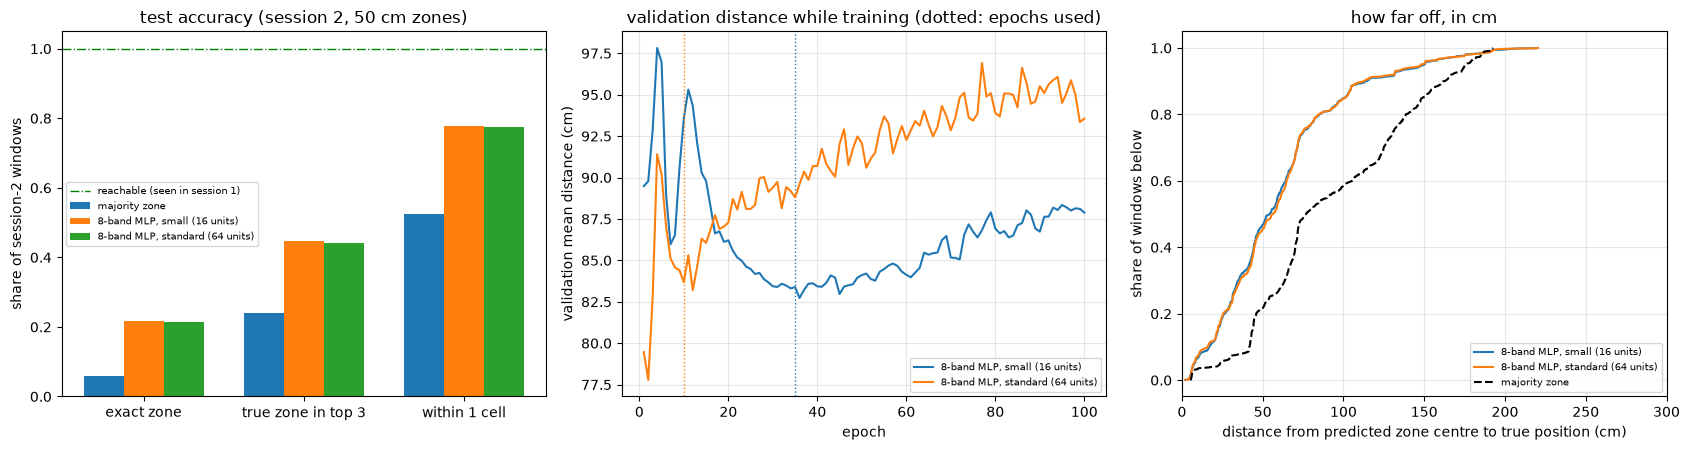

In [22]:
n2 = list(res2)
print(f"{'':<34}{'val mean dist':>14}{'test median':>12}{'test mean':>10}{'test p90':>9}{'top-1':>7}{'seen-only':>10}{'top-3':>7}{'within 1':>9}{'epochs':>8}{'params':>9}   (distances in cm)")
print(f"{'majority zone':<34}{base2['majority_val']['mean_dist_cm']:14.0f}{bm2['median_dist_cm']:12.0f}{bm2['mean_dist_cm']:10.0f}{bm2['p90_dist_cm']:9.0f}{bm2['top1']:7.1%}{bm2['top1_seen']:10.1%}{bm2['top3']:7.0%}{bm2['within1']:9.0%}")
print(f"{'random guess (prior)':<34}{'':>14}{base2['prior_median_dist_cm']:12.0f}{'':>10}{'':>9}{base2['prior_top1']:7.1%}{'':>10}{'':>7}{base2['prior_within1']:9.0%}")
for n in n2:
    r = res2[n]; m = r["test"]
    print(f"{n:<34}{r['val']['mean_dist_cm']:14.0f}{m['median_dist_cm']:12.0f}{m['mean_dist_cm']:10.0f}{m['p90_dist_cm']:9.0f}{m['top1']:7.1%}{m['top1_seen']:10.1%}{m['top3']:7.0%}{m['within1']:9.0%}{r['epochs']:8}{r['params']:9,}")
print(f"\nreachable share of the test (zone seen in session 1): {seen2.mean():.0%}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6)); w = 0.25
rows = [("majority zone", bm2)] + [(n, res2[n]["test"]) for n in n2]
for j, (lab, m) in enumerate(rows):
    ax[0].bar(np.arange(3) + j * w, [m["top1"], m["top3"], m["within1"]], w, label=lab)
ax[0].axhline(seen2.mean(), c="g", ls="-.", lw=1, label="reachable (seen in session 1)")
ax[0].set_xticks(np.arange(3) + w); ax[0].set_xticklabels(["exact zone", "true zone in top 3", "within 1 cell"]); ax[0].set_ylabel("share of session-2 windows"); ax[0].legend(fontsize=7); ax[0].set_title("test accuracy (session 2, 50 cm zones)")
for n in n2:
    ax[1].plot(np.arange(1, len(res2[n]["dist_curve"]) + 1), res2[n]["dist_curve"], label=n); ax[1].axvline(res2[n]["epochs"], c=ax[1].lines[-1].get_color(), ls=":", lw=1)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation mean distance (cm)"); ax[1].set_title("validation distance while training (dotted: epochs used)"); ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3)
for n in n2:
    e = np.sort(res2[n]["test"]["dist"]); ax[2].plot(e, np.arange(1, len(e) + 1) / len(e), label=n)
e = np.sort(bm2["dist"]); ax[2].plot(e, np.arange(1, len(e) + 1) / len(e), "k--", label="majority zone")
ax[2].set_xlim(0, 300); ax[2].set_xlabel("distance from predicted zone centre to true position (cm)"); ax[2].set_ylabel("share of windows below"); ax[2].legend(fontsize=7); ax[2].grid(alpha=0.3); ax[2].set_title("how far off, in cm")
plt.tight_layout()

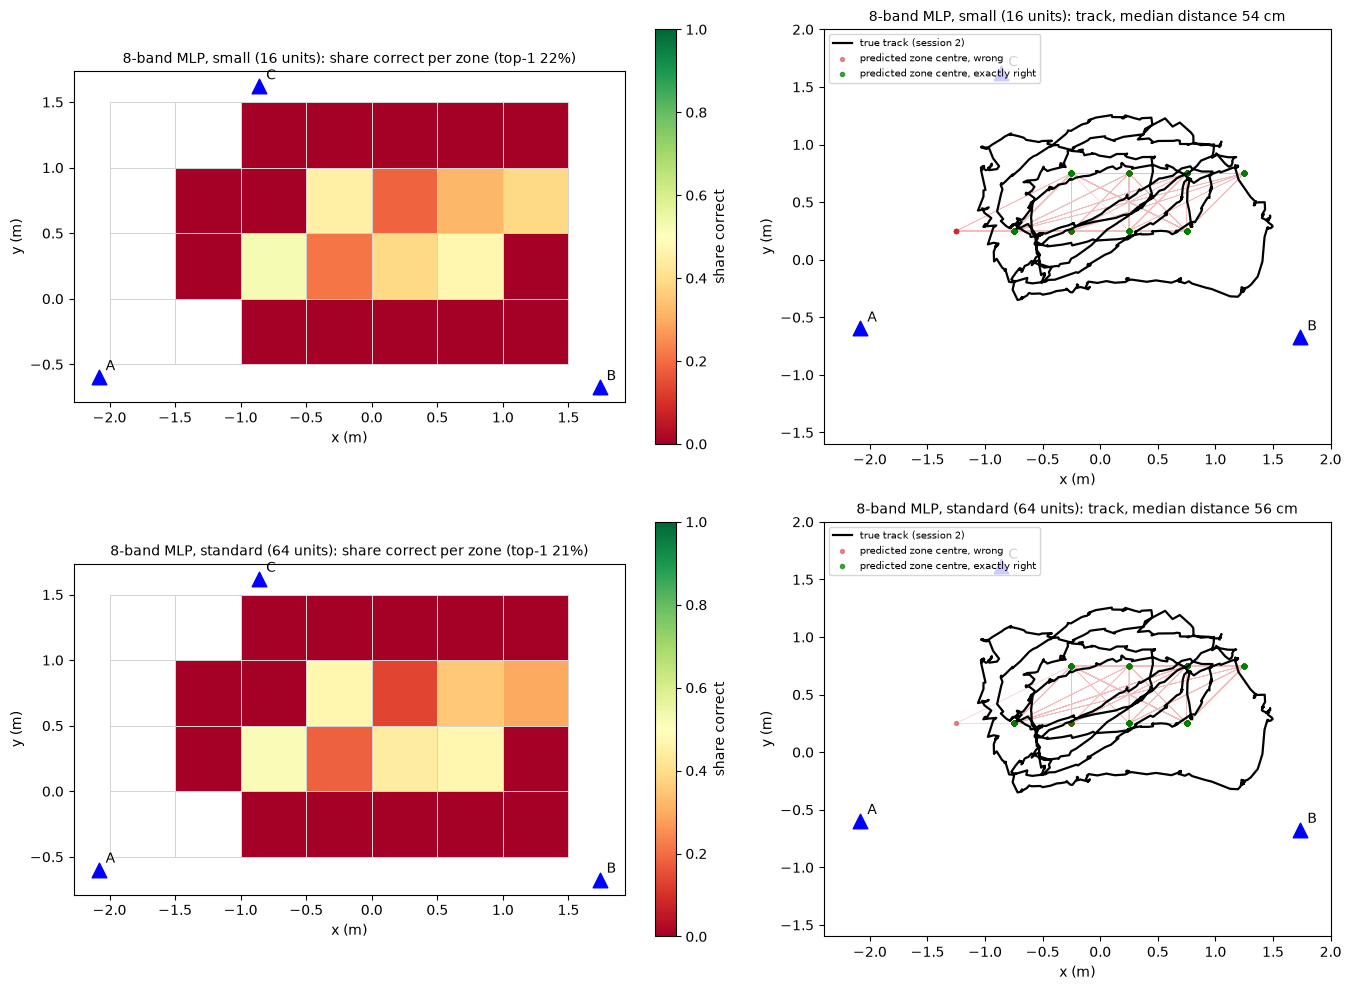

In [23]:
fig, ax = plt.subplots(len(n2), 2, figsize=(14, 5 * len(n2)))
for row, n in zip(ax, n2):
    t = res2[n]["test"]; lo_, hi_ = extent(ZONE)
    g_ok = np.zeros((hi_[1] - lo_[1] + 1, hi_[0] - lo_[0] + 1)); g_n = np.zeros_like(g_ok)
    for (kx, ky), ok in zip(t["true_keys"], t["correct"]):
        g_n[ky - lo_[1], kx - lo_[0]] += 1; g_ok[ky - lo_[1], kx - lo_[0]] += ok
    draw_grid(row[0], ZONE, np.where(g_n > 0, g_ok / np.maximum(g_n, 1), np.nan), "RdYlGn", f"{n}: share correct per zone (top-1 {t['top1']:.0%})", "share correct", 0, 1, unseen2)
    pc = zone_center(t["pred_keys"], ZONE)
    row[1].plot(*Y[te_idx].T, "k-", lw=1.6, label="true track (session 2)", zorder=3); row[1].plot(*pc.T, "-", c="tab:red", lw=0.4, alpha=0.3, zorder=1)
    row[1].scatter(*pc[~t["correct"]].T, s=8, c="tab:red", alpha=0.5, label="predicted zone centre, wrong", zorder=2)
    row[1].scatter(*pc[t["correct"]].T, s=9, c="green", alpha=0.7, label="predicted zone centre, exactly right", zorder=2)
    for ph, (px, py) in ds.phones.items():
        row[1].scatter(px, py, marker="^", s=110, c="b", zorder=5); row[1].annotate(ph, (px, py), xytext=(5, 5), textcoords="offset points")
    row[1].set_aspect("equal"); row[1].set_xlim(-2.4, 2.0); row[1].set_ylim(-1.6, 2.0); row[1].legend(fontsize=7, loc="upper left")
    row[1].set_title(f"{n}: track, median distance {t['median_dist_cm']:.0f} cm", fontsize=10); row[1].set_xlabel("x (m)"); row[1].set_ylabel("y (m)")
plt.tight_layout()
tr_idx, va_idx, fit_idx, te_idx = orig_idx          # restore the session 1+2 -> session 3 split

## Files written
* `trained_models_zones_distance/<model>_zone<size>cm.pt`: for every seed of the final fit, the network weights and the standardisation numbers; the zone classes (the order of the output scores), the epoch count, parameter count and the scores. The architectures are `make_mlp_cls`, `make_spec_cnn`, `make_raw_cnn` above (the last layer has one output per class). The loss used was expected distance + 0.1 x cross-entropy.
* `trained_models_zones_distance/<model>_zone<size>cm_probs.npz`: the predicted probability of every zone for the validation and test windows (`probs_val`, `probs_test`), the class lists (`classes_tr` for the validation run, `classes_fit` for the final fit) and the window indices in the dataset's order.
* `trained_models_zones_distance/results_zones.json`: all scores, updated after every model.

## Notes
* Same protocol as `experiment.ipynb` and `experiment_zones.ipynb`, so the numbers can be compared with both; the regression result for the 8-band MLP (median error 62 cm) is read from `trained_models/summary.json` for the reference line in the sweep figure.
* Session 3 is one session; differences of a few percentage points between models are noise (see the discussion in `experiment.ipynb`).
* The section "Second split" adds `8band_MLP_small16_zone50cm_s1to2.*` and `8band_MLP_zone50cm_s1to2.*` (train/validate on session 1, test on session 2) to the same folder and to `results_zones.json`.